# 04 · Tree-embedding signals (APHD / TOOD) and their conformal validity

**Goals**
1. Fit the ExtraTrees embedder and compare the detection power of five scores on the OOD scenarios.
2. Look at the sensitivity to tree depth (`min_samples_leaf`). This is *for looking, not for tuning*: picking a value because it scores well on the test scenarios would leak OOD information.
3. Answer the open question D0: is TOOD, once conformalized naively, still valid when the test batch contains OOD points?

**Identity used throughout** (`src/conformal_trees/signals/aphd.py`): the average pairwise Hamming distance of a point to a set equals `1 - (average leaf mass of its leaves under that set)`.
Convention: **higher score = more OOD**. The two TOOD uses have opposite signs:
- `tood_batch`: score = leaf mass among the batch itself (OOD points cluster, so they share leaves).
- `ref_aphd`: score = APHD to a fixed ID reference set (OOD points land where little ID mass lives).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from conformal_trees.conformal import conformal_pvalues, empirical_fpr
from conformal_trees.data import build_covariate_shifts, load_dataset, make_splits, mix_batch
from conformal_trees.evaluation import ood_auroc
from conformal_trees.models import GBDTClassifier, TreeEmbedder
from conformal_trees.signals import IsolationForestScore, msp_score, reference_score, tood_batch_score
from conformal_trees.utils import load_config, set_global_seed

pd.set_option("display.max_columns", 50)
cfg = load_config("base.yaml", "models.yaml", "ood_scenarios.yaml")
SEED = cfg["project"]["default_seed"]
ALPHA = cfg["conformal"]["alpha"]
set_global_seed(SEED)

ds = load_dataset("adult")
splits = make_splits(ds.X, ds.y, cfg["splits"], seed=SEED)
X_id = splits.test.X
shifts = {s.name: s for s in build_covariate_shifts(cfg, splits.train.X, ds.numeric)}

## 1. Fit

In [2]:
embedder = TreeEmbedder.from_config(cfg["embedder"], ds.numeric, ds.categorical, seed=SEED).fit(splits.train.X, splits.train.y)
gbdt = GBDTClassifier.from_config(cfg["gbdt"], seed=SEED).fit(splits.train.X, splits.train.y)
iforest = IsolationForestScore(ds.numeric, ds.categorical, seed=SEED).fit(splits.train.X)

emb = {name: embedder.transform(s.X) for name, s in splits if name != "train"}
print({k: v.shape for k, v in emb.items()})

d:\Development\projects for master\Paper researcher\Conformalized Tree-Based Gradient Ensembles for Out-of-Distribution Detection and Recourse\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


{'calib_fit': (4884, 100), 'calib': (9769, 100), 'test': (9769, 100)}


## 2. Detection power: five scores on every scenario
AUROC of ID rows (label 0) versus their shifted copies (label 1), higher score = more OOD.
`tood_batch_pi*` scores the rows inside a **mixed unlabeled batch** where a fraction `pi` of the rows is shifted (this is how TOOD is meant to be used).
**An AUROC clearly below 0.5 is not "bad": it means the signal is informative but its direction is inverted** (the score goes down under shift).

In [3]:
def per_sample_scores(X):
    return {
        "ref_aphd": reference_score(embedder.transform(X), emb["calib_fit"]),
        "iforest": iforest.score(X),
        "msp": msp_score(gbdt.predict_proba(X)[:, 1]),
    }

base = per_sample_scores(X_id)
rows = []
for name, s in shifts.items():
    X_ood = s.apply(X_id, seed=SEED)
    ood = per_sample_scores(X_ood)
    row = {"scenario": name, **{k: ood_auroc(base[k], ood[k]) for k in base}}
    for pi in (0.1, 0.5):
        batch, is_ood = mix_batch(X_id, X_ood, pi, seed=SEED)
        sc = tood_batch_score(embedder.transform(batch))
        row[f"tood_batch_pi{pi}"] = ood_auroc(sc[~is_ood], sc[is_ood])
    rows.append(row)
power = pd.DataFrame(rows).set_index("scenario")
power.round(3)

,ref_aphd,iforest,msp,tood_batch_pi0.1,tood_batch_pi0.5
scenario,,,,,
mean_shift@0.25,0.547,0.526,0.560,0.469,0.580
mean_shift@0.5,0.575,0.545,0.596,0.458,0.593
mean_shift@1,0.655,0.639,0.665,0.510,0.734
mean_shift@2,0.740,0.813,0.752,0.662,0.928
mean_shift@4,0.798,0.959,0.744,0.912,1.000
gaussian_noise@0.25,0.501,0.516,0.500,0.482,0.530
gaussian_noise@0.5,0.497,0.542,0.493,0.503,0.555
gaussian_noise@1,0.482,0.612,0.478,0.525,0.606
gaussian_noise@2,0.458,0.732,0.449,0.602,0.720


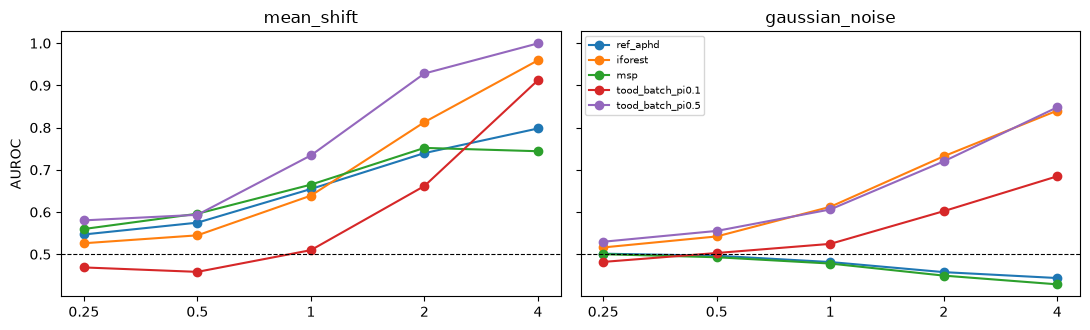

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, kind in zip(axes, cfg["covariate_shift"]["kinds"]):
    sub = power[power.index.str.startswith(kind)]
    sev = [float(i.split("@")[1]) for i in sub.index]
    for col in power.columns:
        ax.plot(sev, sub[col], "o-", label=col)
    ax.axhline(0.5, color="k", ls="--", lw=0.8); ax.set_xscale("log"); ax.set_title(kind)
    ax.set_xticks(sev); ax.set_xticklabels([f"{v:g}" for v in sev]); ax.minorticks_off()
axes[0].set_ylabel("AUROC"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. Sensitivity to tree depth (look, do not tune)
Same two scenarios, different `min_samples_leaf`. If the AUROC crosses 0.5 as depth changes, the **direction** of the signal is a function of a hyperparameter, and it cannot be chosen without OOD labels.

In [5]:
rows = []
for msl in (1, 5, 20, 50, 200):
    e = TreeEmbedder(ds.numeric, ds.categorical, n_estimators=cfg["embedder"]["n_estimators"],
                     min_samples_leaf=msl, n_jobs=cfg["embedder"]["n_jobs"], seed=SEED).fit(splits.train.X, splits.train.y)
    ref, e_id = e.transform(splits.calib_fit.X), e.transform(X_id)
    for name in ("mean_shift@1", "gaussian_noise@2"):
        X_ood = shifts[name].apply(X_id, seed=SEED)
        batch, is_ood = mix_batch(X_id, X_ood, 0.1, seed=SEED)
        sc = tood_batch_score(e.transform(batch))
        rows.append({"min_samples_leaf": msl, "scenario": name,
                     "ref_aphd": ood_auroc(reference_score(e_id, ref), reference_score(e.transform(X_ood), ref)),
                     "tood_batch_pi0.1": ood_auroc(sc[~is_ood], sc[is_ood])})
pd.DataFrame(rows).pivot(index="min_samples_leaf", columns="scenario").round(3)

ref_aphd              tood_batch_pi0.1             
scenario         gaussian_noise@2 mean_shift@1 gaussian_noise@2 mean_shift@1
min_samples_leaf                                                            
1                           0.458        0.655            0.602        0.510
5                           0.672        0.691            0.393        0.415
20                          0.703        0.658            0.351        0.459
50                          0.664        0.645            0.382        0.461
200                         0.600        0.584            0.427        0.479

## 4. Validity under contamination (the D0 question)
Calibrate on a **clean** ID batch (`calib`), then score a test batch with the same procedure and look at the **false-positive rate on the ID rows of the batch** at level alpha.
- `naive TOOD pi=0`: the batch is all ID, so exchangeability holds at the batch level. Expect FPR ≈ alpha.
- `naive TOOD pi>0`: ID rows are scored against a batch that contains OOD rows, so their scores are no longer exchangeable with the calibration scores. Does the FPR stay ≤ alpha?
- `reference APHD`: a fixed function of the row (reference = `calib_fit`), so split-conformal validity holds at any contamination.
A single seed fluctuates by about sqrt(alpha(1-alpha)/n_cal) (Bates et al.), so we report mean ± sd over 5 seeds.

In [6]:
records = []
for seed in cfg["project"]["seeds"][:5]:
    sp = make_splits(ds.X, ds.y, cfg["splits"], seed=seed)
    e = TreeEmbedder.from_config(cfg["embedder"], ds.numeric, ds.categorical, seed=seed).fit(sp.train.X, sp.train.y)
    scen = {s.name: s for s in build_covariate_shifts(cfg, sp.train.X, ds.numeric)}
    e_cal, e_ref = e.transform(sp.calib.X), e.transform(sp.calib_fit.X)
    cal_batch_scores = tood_batch_score(e_cal)
    p_ref = conformal_pvalues(reference_score(e_cal, e_ref), reference_score(e.transform(sp.test.X), e_ref))
    for name in ("mean_shift@1", "gaussian_noise@2"):
        X_ood = scen[name].apply(sp.test.X, seed=seed)
        for pi in (0.0, 0.1, 0.5):
            batch, is_ood = mix_batch(sp.test.X, X_ood, pi, seed=seed)
            p = conformal_pvalues(cal_batch_scores, tood_batch_score(e.transform(batch)))
            records.append({"scenario": name, "method": f"naive TOOD pi={pi}", "seed": seed, "fpr": empirical_fpr(p[~is_ood], ALPHA)})
        records.append({"scenario": name, "method": "reference APHD", "seed": seed, "fpr": empirical_fpr(p_ref, ALPHA)})
validity = pd.DataFrame(records)
print(f"target alpha = {ALPHA}")
validity.groupby(["scenario", "method"])["fpr"].agg(["mean", "std"]).round(4)

target alpha = 0.05


mean     std
scenario         method                           
gaussian_noise@2 naive TOOD pi=0.0  0.0466  0.0100
                 naive TOOD pi=0.1  0.0443  0.0088
                 naive TOOD pi=0.5  0.0382  0.0071
                 reference APHD     0.0467  0.0027
mean_shift@1     naive TOOD pi=0.0  0.0466  0.0100
                 naive TOOD pi=0.1  0.0356  0.0090
                 naive TOOD pi=0.5  0.0001  0.0003
                 reference APHD     0.0467  0.0027

## 5. Notes to carry into `docs/decisions.md`
- Which scores are above 0.5 and which are inverted on the real Adult? Is the direction stable across severities and kinds?
- Does the `min_samples_leaf` table cross 0.5? If yes, the inductive signal needs a two-sided test (or a direction chosen without OOD labels).
- At which contamination does naive TOOD exceed alpha, and by how much (compare with the sd over seeds)?
- `reference APHD` should sit at or below alpha within noise. If it is clearly above, there is a bug in the split protocol: stop and investigate.